# 02 · Block 1 — colour mask

Goal: `yellow_mask(rgb) → (H, W)` in 0..1. One on paint, zero elsewhere, robust to lighting.

In [2]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Choosing a colour score

One number per pixel. It must be ~0 on any grey (asphalt, white paint, shadow) and high on yellow. Test candidates on colours the camera may see.

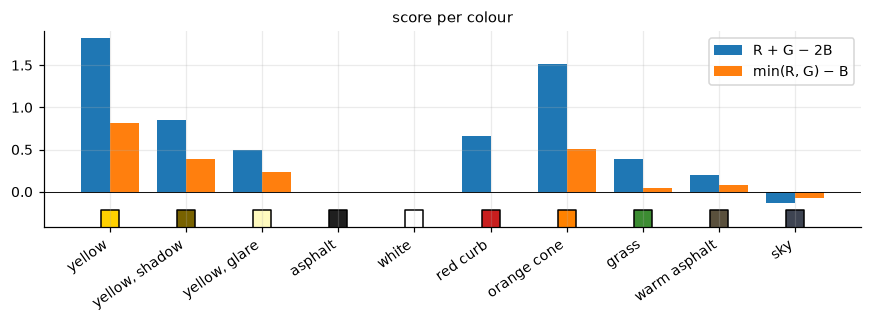

In [3]:
swatches = {
    "yellow": (255, 209, 0), "yellow, shadow": (120, 98, 0), "yellow, glare": (255, 250, 190),
    "asphalt": (31, 31, 31), "white": (255, 255, 255), "red curb": (200, 30, 30),
    "orange cone": (255, 130, 0), "grass": (60, 140, 50), "warm asphalt": (90, 80, 60), "sky": (62, 68, 82),
}
rgb = np.array(list(swatches.values()), dtype=np.float32) / 255
r, g, b = rgb.T
scores = {"R + G − 2B": r + g - 2 * b, "min(R, G) − B": np.minimum(r, g) - b}

fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(swatches))
for i, (name, s) in enumerate(scores.items()):
    ax.bar(x + (i - 0.5) * 0.38, s, 0.38, label=name)
ax.scatter(x, np.full(len(x), -0.32), c=rgb, s=140, marker="s", edgecolors="k")
ax.set_xticks(x, swatches, rotation=35, ha="right")
ax.axhline(0, color="k", lw=0.6)
ax.set(ylim=(-0.42, 1.9), title="score per colour")
ax.legend()
plt.tight_layout()
plt.show()

Both scores are 0 on grey: with `R = G = B = c`, `c + c − 2c = 0` and `min(c, c) − c = 0`.

`R + G − 2B` also fires on red and green: one strong channel is enough. Yellow is red **and** green, so

$$\text{yellowness} = \min(R, G) - B$$

is high only when both exceed blue. Red curbs and grass drop to ~0. Orange still scores — it is close to yellow; geometry rejects it later (05).

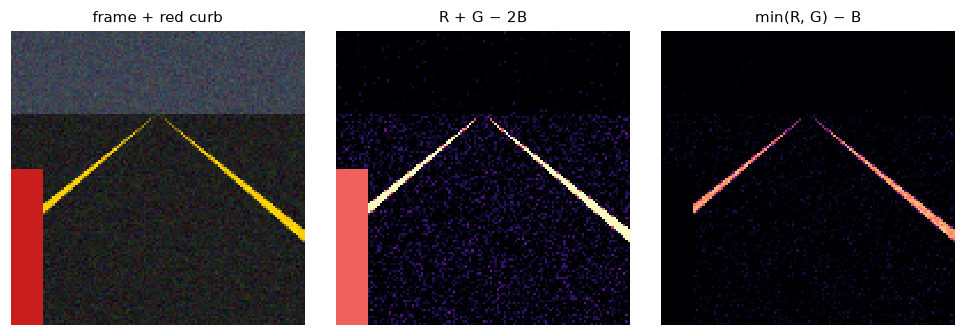

In [7]:
frame = SyntheticTrack(noise=10).render(seed=0)
frame[60:, :14] = (200, 30, 30)  # red curb on the left edge
f = frame.astype(np.float32) / 255
show(
    [frame, np.clip(f[..., 0] + f[..., 1] - 2 * f[..., 2], 0, 1), np.clip(np.minimum(f[..., 0], f[..., 1]) - f[..., 2], 0, 1)],
    ["frame + red curb", "R + G − 2B", "min(R, G) − B"],
)

## From score to mask

A soft ramp instead of a hard threshold:

$$m = \operatorname{clip}\!\left(\frac{\text{yellowness} - \text{low}}{\text{high} - \text{low}},\; 0,\; 1\right)$$

Anti-aliased line edges keep fractional values. Block 2 averages them to place a line with sub-pixel precision; a hard threshold would round that information away.

`low` must sit above road noise, `high` below the dimmest paint we care about (shadowed yellow ≈ 0.38).

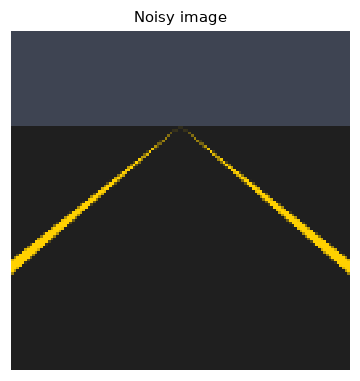

In [21]:
plt.figure(figsize=(4, 4))
plt.imshow(SyntheticTrack(noise=0).render(seed=0))
plt.title("Noisy image")
plt.axis("off")
plt.show()

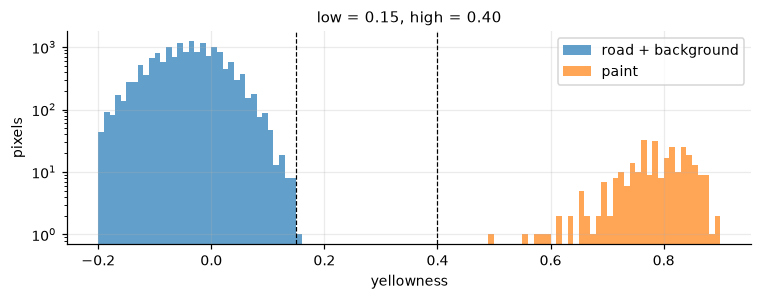

In [26]:
clean = SyntheticTrack().render().astype(np.float32) / 255
clean_y = np.minimum(clean[..., 0], clean[..., 1]) - clean[..., 2]
noisy = SyntheticTrack(noise=10).render(seed=0).astype(np.float32) / 255
y = np.minimum(noisy[..., 0], noisy[..., 1]) - noisy[..., 2]

fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(-0.2, 0.9, 111)
ax.hist(y[clean_y < 0.01], bins, alpha=0.7, label="road + background", log=True)
ax.hist(y[clean_y > 0.6], bins, alpha=0.7, label="paint", log=True)
for t in (0.15, 0.40):
    ax.axvline(t, color="k", ls="--", lw=0.8)
ax.set(xlabel="yellowness", ylabel="pixels", title="low = 0.15, high = 0.40")
ax.legend()
plt.tight_layout()
plt.show()

Road noise stays below `low`; paint sits above `high`.

This cell saves the block to `lanedet/mask.py`. The next cell imports it.

In [27]:
%%writefile lanedet/mask.py
"""Block 1 - colour mask: how much each pixel looks like a yellow line, 0..1."""

import numpy as np


def to_float(frame: np.ndarray) -> np.ndarray:
    """RGB frame (H, W, 3[+alpha]) as float32 in [0, 1]."""
    frame = np.asarray(frame)[..., :3]
    if frame.dtype == np.uint8:
        return frame.astype(np.float32) / 255.0
    return frame.astype(np.float32)


def yellowness(rgb: np.ndarray) -> np.ndarray:
    """min(R, G) - B: high only when red AND green both exceed blue."""
    return np.minimum(rgb[..., 0], rgb[..., 1]) - rgb[..., 2]


def yellow_mask(rgb: np.ndarray, low: float = 0.15, high: float = 0.40) -> np.ndarray:
    """Soft mask: 0 below `low`, linear ramp, 1 above `high`."""
    return np.clip((yellowness(rgb) - low) / (high - low), 0.0, 1.0)

Overwriting lanedet/mask.py


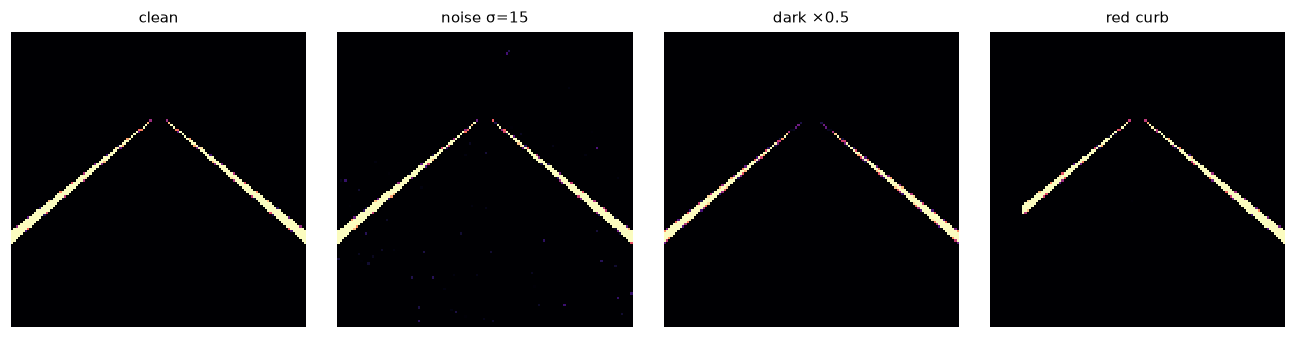

In [28]:
from lanedet.mask import to_float, yellow_mask

tests = {
    "clean": SyntheticTrack().render(),
    "noise σ=15": SyntheticTrack(noise=15).render(seed=1),
    "dark ×0.5": SyntheticTrack(brightness=0.5).render(),
    "red curb": frame,
}
show([yellow_mask(to_float(t)) for t in tests.values()], list(tests), cols=4)

## Check

In [29]:
m = yellow_mask(to_float(np.array([[(255, 209, 0), (31, 31, 31), (255, 255, 255), (200, 30, 30), (120, 98, 0)]], np.uint8)))[0]
assert m[0] == 1 and m[1] == 0 and m[2] == 0 and m[3] == 0 and m[4] > 0.9
noisy_mask = yellow_mask(to_float(SyntheticTrack(noise=15).render(seed=1)))
clean_mask = yellow_mask(to_float(SyntheticTrack().render()))
assert np.abs(noisy_mask - clean_mask).mean() < 0.01

## Practice

Three exercises. **Predict first, then run.** Matching lesson: `lesson_centerline.html` → Block 1.

### P1 · Predict — dirty-white paint

Pixel `(220, 215, 170)`. Work out on paper:
1. `min(R, G) − B` (in 0..1 units)
2. Mask value with `low = 0.15`, `high = 0.40`
3. Should a lane detector accept it?

Write your answers down, then run the next cell.

In [30]:
px = np.array([[(220, 215, 170)]], np.uint8)
from lanedet.mask import yellowness
print(f'yellowness = {yellowness(to_float(px))[0, 0]:.3f}')
print(f'mask       = {yellow_mask(to_float(px))[0, 0]:.3f}')


yellowness = 0.176
mask       = 0.106


<details><summary>Explanation (open after running)</summary>

`min(220, 215) − 170 = 45` → `45/255 ≈ 0.18`. Just above `low = 0.15`, so mask ≈ `(0.18 − 0.15)/0.25 ≈ 0.11`.
Weak, not zero. Faded yellow paint and dirty white look alike in RGB — the mask hedges with a small value
and lets geometry (Block 4: width matching) decide. A hard threshold would force a yes/no here.
</details>

### P2 · Build — why a soft ramp, not a hard threshold?

Lesson claim: the soft ramp keeps sub-pixel information that a hard threshold destroys. Test it.

Setup below renders a single row with a 3.4 px yellow line at a **known** centre, anti-aliased
(edge pixels are a blend of yellow and asphalt). We slide the line in 0.05 px steps and measure the
centroid with the same formula Block 2 uses: `Σ p·(u + 0.5) / Σ p`.

**Your job:** implement `yellow_mask_hard` in the next cell. Then run the plot cell.

In [31]:
def render_line_row(centre, width=3.4, W=32):
    """One image row (1, W, 3) float, yellow line of `width` px centred at `centre`."""
    u = np.arange(W)
    left, right = centre - width / 2, centre + width / 2
    cover = np.clip(np.minimum(u + 1, right) - np.maximum(u, left), 0, 1)  # fraction of pixel painted
    yellow, asphalt = np.array([255, 209, 0]) / 255, np.array([31, 31, 31]) / 255
    return (cover[:, None] * yellow + (1 - cover[:, None]) * asphalt)[None].astype(np.float32)


def centroid(mask_row):
    p = mask_row[0]
    return (p * (np.arange(len(p)) + 0.5)).sum() / p.sum()


def yellow_mask_hard(rgb, threshold=0.275):
    """Binary mask: 1.0 where yellowness > threshold, else 0.0. Same shape as yellow_mask output."""
    # TODO(human): 1-2 lines. Reuse yellowness(rgb). Return float32, not bool
    #   (centroid() multiplies by it).
    raise NotImplementedError


In [ ]:
true_c = np.arange(14.0, 16.0, 0.05)
soft = [centroid(yellow_mask(render_line_row(c))) for c in true_c]
hard = [centroid(yellow_mask_hard(render_line_row(c))) for c in true_c]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(true_c, true_c, 'k--', lw=0.8, label='truth')
ax.plot(true_c, soft, label='soft ramp')
ax.step(true_c, hard, where='mid', label='hard threshold')
ax.set(xlabel='true line centre (px)', ylabel='measured centre (px)', title='sub-pixel precision')
ax.legend()
plt.tight_layout()
plt.show()

err_soft = np.abs(np.array(soft) - true_c)
err_hard = np.abs(np.array(hard) - true_c)
print(f'max error  soft = {err_soft.max():.3f} px   hard = {err_hard.max():.3f} px')
assert err_soft.max() < err_hard.max(), 'soft ramp should beat the hard threshold'


**Question:** the hard curve is a staircase. How tall is each step, and why that size?
Bonus: at 4 m ahead, 1 px ≈ how many cm? (Use `track.distance` and the camera model from Lab 04.)

### P3 · Compare — which score rejects the red curb?

Predict: on the red-curb frame, how many curb pixels pass each score? Then run.

In [ ]:
curb = np.zeros(frame.shape[:2], bool)
curb[60:, :14] = True
f = to_float(frame)
rg2b = np.clip((f[..., 0] + f[..., 1] - 2 * f[..., 2] - 0.15) / 0.25, 0, 1)
ming = yellow_mask(f)
table([
    {'score': 'R + G − 2B',    'curb pixels > 0.5': int((rg2b[curb] > 0.5).sum()), 'of': int(curb.sum())},
    {'score': 'min(R, G) − B', 'curb pixels > 0.5': int((ming[curb] > 0.5).sum()), 'of': int(curb.sum())},
])


## Next

Lab 03 — collapse this mask into a 1-D profile and find the lines in it.